In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

импорт библиотек


In [3]:
titanic = pd.read_csv('train.csv')

импортируем файл


In [4]:
titanic.columns = titanic.columns.str.lower()
print(titanic.columns.tolist())

['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']


приведение названий столбцов к нижнему регистру

In [6]:
print("Количество строк и столбцов:", titanic.shape)
print()
print("Столбцы датасета:")
print(titanic.columns.tolist())
print()
print("Типы данных столбцов:")
print(titanic.dtypes)
print()
titanic.head()

Количество строк и столбцов: (891, 12)

Столбцы датасета:
['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked']

Типы данных столбцов:
passengerid      int64
survived         int64
pclass           int64
name            object
sex             object
age            float64
sibsp            int64
parch            int64
ticket          object
fare           float64
cabin           object
embarked        object
dtype: object



,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


вывод размера, названия столбцов,типы данных и первые 5 строк

In [7]:
# Количество пассажиров каждого класса
print("Количество пассажиров по классам:")
print(titanic['pclass'].value_counts().sort_index())
print()

# Количество мужчин и женщин
print("Количество мужчин и женщин:")
print(titanic['sex'].value_counts())
print()

# Разделение на возрастные группы
bins = [0, 12, 18, 30, 50, 100]
labels = ['Дети (0-12)', 'Подростки (13-18)', 'Молодые (19-30)',
          'Взрослые (31-50)', 'Пожилые (51+)']
titanic['age_group'] = pd.cut(titanic['age'], bins=bins, labels=labels, right=True)

print("Распределение по возрастным группам:")
print(titanic['age_group'].value_counts().sort_index())
print()

# Средний возраст
print(f"Средний возраст пассажиров: {titanic['age'].mean():.2f} лет")
print()

# Медианный возраст
print(f"Медианный возраст пассажиров: {titanic['age'].median():.2f} лет")
print()

# Средняя стоимость билета
print(f"Средняя стоимость билета: {titanic['fare'].mean():.2f}")

Количество пассажиров по классам:
pclass
1    216
2    184
3    491
Name: count, dtype: int64

Количество мужчин и женщин:
sex
male      577
female    314
Name: count, dtype: int64

Распределение по возрастным группам:
age_group
Дети (0-12)           69
Подростки (13-18)     70
Молодые (19-30)      270
Взрослые (31-50)     241
Пожилые (51+)         64
Name: count, dtype: int64

Средний возраст пассажиров: 29.70 лет

Медианный возраст пассажиров: 28.00 лет

Средняя стоимость билета: 32.20


In [8]:
# Средняя стоимость билета по классам
print("Средняя стоимость билета по классам:")
print(titanic.groupby('pclass')['fare'].mean().round(2))
print()

# Средний возраст по классам
print("Средний возраст пассажиров по классам:")
print(titanic.groupby('pclass')['age'].mean().round(2))
print()

# Количество мужчин и женщин в каждом классе
print("Количество мужчин и женщин по классам:")
print(titanic.groupby(['pclass', 'sex']).size().unstack())
print()

# В каком классе было больше всего пассажиров
most_populated = titanic['pclass'].value_counts().idxmax()
print(f"Больше всего пассажиров было в {most_populated} классе "
      f"({titanic['pclass'].value_counts().max()} чел.)")
print()

Средняя стоимость билета по классам:
pclass
1    84.15
2    20.66
3    13.68
Name: fare, dtype: float64

Средний возраст пассажиров по классам:
pclass
1    38.23
2    29.88
3    25.14
Name: age, dtype: float64

Количество мужчин и женщин по классам:
sex     female  male
pclass              
1           94   122
2           76   108
3          144   347

Больше всего пассажиров было в 3 классе (491 чел.)



In [9]:
# Сводная таблица по классам
summary = titanic.groupby('pclass').agg(
    passengers=('survived', 'count'),
    avg_fare=('fare', 'mean'),
    avg_age=('age', 'mean'),
    survival_rate=('survived', 'mean')
).round(2)
print(summary)

        passengers  avg_fare  avg_age  survival_rate
pclass                                              
1              216     84.15    38.23           0.63
2              184     20.66    29.88           0.47
3              491     13.68    25.14           0.24


In [10]:
print("ВЫВОД:")
print("1. Пассажиры 1 класса платили за билет значительно больше "
      "(в среднем ~84), чем пассажиры 2 (~20) и 3 (~13) классов.")
print("2. Средний возраст пассажиров 1 класса выше, чем у 2 и 3 классов.")
print("3. Больше всего пассажиров было в 3 классе (самый многочисленный).")
print("4. Доля выживших выше в 1 классе, ниже — в 3 классе.")

ВЫВОД:
1. Пассажиры 1 класса платили за билет значительно больше (в среднем ~84), чем пассажиры 2 (~20) и 3 (~13) классов.
2. Средний возраст пассажиров 1 класса выше, чем у 2 и 3 классов.
3. Больше всего пассажиров было в 3 классе (самый многочисленный).
4. Доля выживших выше в 1 классе, ниже — в 3 классе.


In [11]:
# Самый дорогой билет
max_fare_row = titanic.loc[titanic['fare'].idxmax()]
print("Самый дорогой билет:")
print(f"  Стоимость: {max_fare_row['fare']}")
print(f"  Класс: {max_fare_row['pclass']}")
print(f"  Возраст: {max_fare_row['age']}")
print(f"  Пол: {max_fare_row['sex']}")
print(f"  Выжил: {'Да' if max_fare_row['survived'] == 1 else 'Нет'}")

Самый дорогой билет:
  Стоимость: 512.3292
  Класс: 1
  Возраст: 35.0
  Пол: female
  Выжил: Да


In [12]:
# Общее количество выживших и погибших
print("Общее количество выживших и погибших:")
print(titanic['survived'].value_counts().rename({0: 'Погибшие', 1: 'Выжившие'}))
print()

# Выживаемость мужчин и женщин
print("Выживаемость по полу (среднее значение survived):")
print(titanic.groupby('sex')['survived'].mean().round(3))
print()

# Выживаемость мужчин и женщин для каждого класса
print("Выживаемость по полу и классу:")
survival_by_class_sex = titanic.groupby(['pclass', 'sex'])['survived'].mean().round(3)
print(survival_by_class_sex.unstack())
print()

# Группа с наибольшей долей выживших
group_survival = titanic.groupby(['pclass', 'sex'])['survived'].mean()
best_group = group_survival.idxmax()
best_rate = group_survival.max()
print(f"Наибольшая доля выживших: класс {best_group[0]}, пол — {best_group[1]} "
      f"({best_rate:.1%})")

Общее количество выживших и погибших:
survived
Погибшие    549
Выжившие    342
Name: count, dtype: int64

Выживаемость по полу (среднее значение survived):
sex
female    0.742
male      0.189
Name: survived, dtype: float64

Выживаемость по полу и классу:
sex     female   male
pclass               
1        0.968  0.369
2        0.921  0.157
3        0.500  0.135

Наибольшая доля выживших: класс 1, пол — female (96.8%)


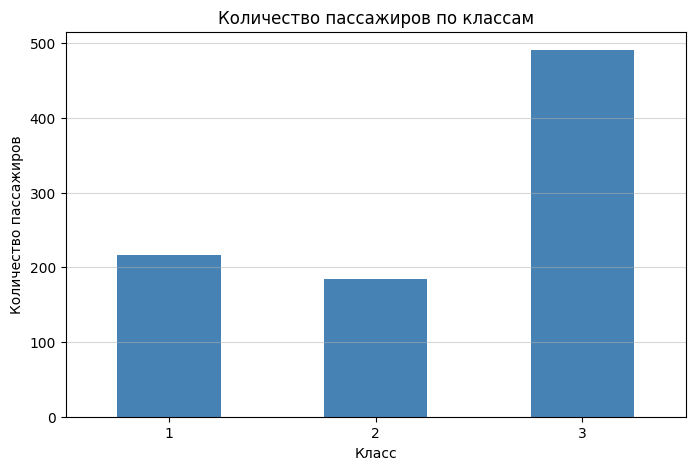

In [13]:
# График 1: Количество пассажиров по классам
plt.figure(figsize=(8, 5))
titanic['pclass'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Количество пассажиров по классам')
plt.xlabel('Класс')
plt.ylabel('Количество пассажиров')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.5)
plt.show()

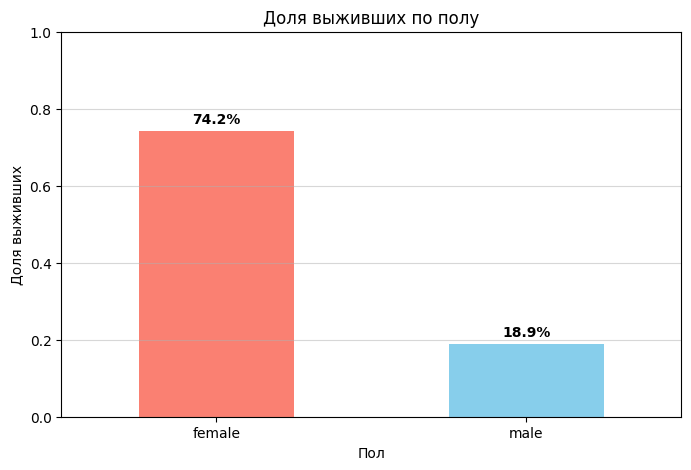

In [14]:
# График 2: Выживаемость по полу
plt.figure(figsize=(8, 5))
survival_sex = titanic.groupby('sex')['survived'].mean()
survival_sex.plot(kind='bar', color=['salmon', 'skyblue'])
plt.title('Доля выживших по полу')
plt.xlabel('Пол')
plt.ylabel('Доля выживших')
plt.xticks(rotation=0)
plt.ylim(0, 1)
for i, v in enumerate(survival_sex):
    plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')
plt.grid(axis='y', alpha=0.5)
plt.show()

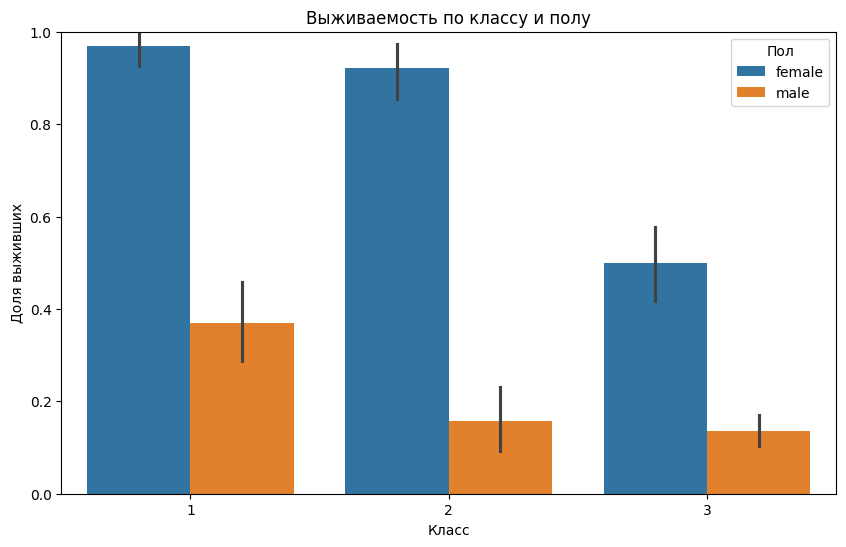

In [15]:
# Дополнительный график: Выживаемость по классу и полу
plt.figure(figsize=(10, 6))
sns.barplot(data=titanic, x='pclass', y='survived', hue='sex')
plt.title('Выживаемость по классу и полу')
plt.xlabel('Класс')
plt.ylabel('Доля выживших')
plt.ylim(0, 1)
plt.legend(title='Пол')
plt.show()

In [16]:
# Создаём признак «семья на борту»
titanic['family_size'] = titanic['sibsp'] + titanic['parch']
titanic['has_family'] = titanic['family_size'] > 0

# Сравнение выживаемости
print("Выживаемость в зависимости от наличия семьи:")
print(titanic.groupby('has_family')['survived'].mean().round(3))
print()

# Детальный анализ по размеру семьи
print("Выживаемость по размеру семьи:")
print(titanic.groupby('family_size')['survived'].agg(['mean', 'count']).round(3))

Выживаемость в зависимости от наличия семьи:
has_family
False    0.304
True     0.506
Name: survived, dtype: float64

Выживаемость по размеру семьи:
              mean  count
family_size              
0            0.304    537
1            0.553    161
2            0.578    102
3            0.724     29
4            0.200     15
5            0.136     22
6            0.333     12
7            0.000      6
10           0.000      7


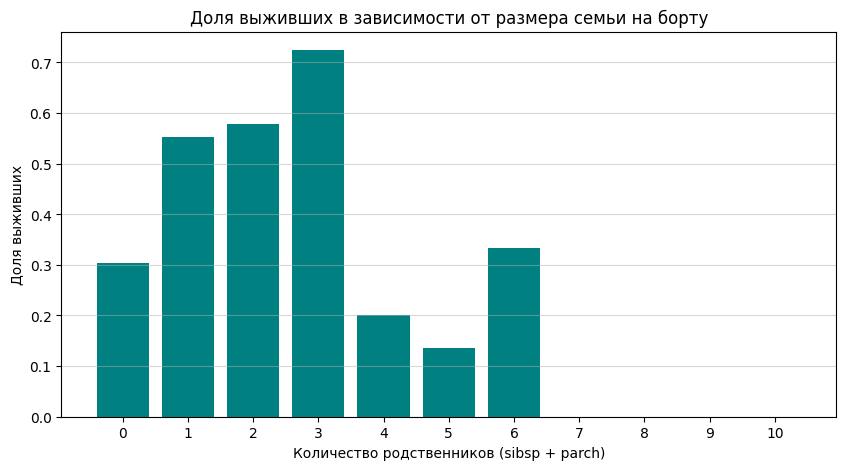

In [17]:
# Визуализация ответа на собственный вопрос
plt.figure(figsize=(10, 5))
family_survival = titanic.groupby('family_size')['survived'].mean()
plt.bar(family_survival.index, family_survival.values, color='teal')
plt.title('Доля выживших в зависимости от размера семьи на борту')
plt.xlabel('Количество родственников (sibsp + parch)')
plt.ylabel('Доля выживших')
plt.xticks(range(0, 11))
plt.grid(axis='y', alpha=0.5)
plt.show()

Итоговые выводы по работе:

Класс пассажира — ключевой фактор: пассажиры 1 класса платили больше, были старше и выживали чаще.

Пол — женщины выживали значительно чаще мужчин (~74% против ~19%).

Возраст — дети имели повышенные шансы на спасение.

Комбинация «класс + пол» — наилучшая выживаемость у женщин 1–2 классов, наихудшая — у мужчин 3 класса.

Семья — наличие 1–3 родственников повышало шансы на выживание, большие семьи — понижали.